# 07 — Ridge Regression


# ML Course — Practical Notebook
**Target:** `price_etb`  
**Dataset:** `Practical_Dataset for ML.xlsx` (sheet: `Data`)  
**Split:** 80% train / 20% test, `random_state=42`

This notebook is designed for learning and assignment discussion. Run cells from top to bottom. Read the interpretation prompts and write down what your actual results mean. Do not report example or assumed metrics; use the values produced by your run.

## Learning objectives
- Understand why ordinary least squares can become unstable with correlated predictors.
- Use L2 regularization to shrink coefficients.
- Tune `alpha` using cross-validation on training data only.
- Compare training and test performance with regression metrics.

## 1. Import libraries

In [3]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
TARGET = "price_etb"

## 2. Load and inspect the dataset

The loader checks common project locations. If your workbook is elsewhere, update `DATA_PATH` below.

In [4]:
possible_paths = [
    Path("data") / "Practical_Dataset for ML.xlsx",
    Path("ML_Course") / "data" / "Practical_Dataset for ML.xlsx",
    Path("..") / "data" / "Practical_Dataset for ML.xlsx",
      Path("..") / ".." / "data" / "Practical_Dataset for ML.xlsx",
    Path("Practical_Dataset for ML.xlsx"),
]
DATA_PATH = next((p for p in possible_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Workbook not found. Place 'Practical_Dataset for ML.xlsx' in the project's data/ folder "
        "or set DATA_PATH to its full path."
    )

df = pd.read_excel(DATA_PATH, sheet_name="Data")
print("Loaded:", DATA_PATH)
print("Shape:", df.shape)
display(df.head())
display(df.dtypes.to_frame("dtype"))

Loaded: ..\..\data\Practical_Dataset for ML.xlsx
Shape: (3000, 17)


,house_id,size_sqm,num_bedrooms,num_bathrooms,floor_level,age_years,renovated,distance_to_bole_km,distance_to_main_road_m,has_garage,parking_spaces,has_garden,security_service,water_supply_hours_per_day,school_rating,days_on_market,price_etb
0,AA-10000,84.8,3,3,0,12,1,9.54,195,1,1,0,1,18.1,4.2,56,4664000
1,AA-10001,142.1,4,3,12,21,0,2.03,119,1,3,0,1,9.1,6.1,19,6209000
2,AA-10002,110.3,3,3,0,6,0,6.96,260,0,0,1,0,24.0,6.7,19,5804000
3,AA-10003,32.0,1,1,11,5,0,7.28,157,0,0,0,0,13.5,4.6,74,1134000
4,AA-10004,61.9,2,1,6,13,0,10.04,153,1,2,0,1,18.1,7.5,12,1810000


,dtype
house_id,str
size_sqm,float64
num_bedrooms,int64
num_bathrooms,int64
floor_level,int64
age_years,int64
renovated,int64
distance_to_bole_km,float64
distance_to_main_road_m,int64
has_garage,int64


## 3. Select features and split once

We exclude the target and the identifier `house_id`. Only numeric predictors are used in this teaching notebook. If a feature would not be known when the prediction is made, exclude it to avoid leakage (for example, `days_on_market` may be unavailable when setting an initial listing price).

In [5]:
if TARGET not in df.columns:
    raise KeyError(f"Target column {TARGET!r} not found. Available columns: {list(df.columns)}")

excluded = {TARGET, "house_id"}
numeric_features = df.select_dtypes(include=np.number).columns.tolist()
FEATURES = [c for c in numeric_features if c not in excluded]

if not FEATURES:
    raise ValueError("No numeric predictor columns were found.")

X = df[FEATURES].copy()
y = pd.to_numeric(df[TARGET], errors="coerce")
valid = y.notna()
X, y = X.loc[valid], y.loc[valid]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Features:", FEATURES)
print(f"Train rows: {len(X_train):,}; test rows: {len(X_test):,}")
print("Note: preprocessing is fitted within each training fold/pipeline.")

Features: ['size_sqm', 'num_bedrooms', 'num_bathrooms', 'floor_level', 'age_years', 'renovated', 'distance_to_bole_km', 'distance_to_main_road_m', 'has_garage', 'parking_spaces', 'has_garden', 'security_service', 'water_supply_hours_per_day', 'school_rating', 'days_on_market']
Train rows: 2,400; test rows: 600
Note: preprocessing is fitted within each training fold/pipeline.


## 4. Define evaluation metrics

MAE and RMSE are in the target's units (ETB). Lower is better. R² is usually better when higher; a negative test R² means the model performed worse than predicting the test-set mean.

In [6]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred),
    }

def evaluate_model(name, estimator, X_train, X_test, y_train, y_test):
    estimator.fit(X_train, y_train)
    train_pred = estimator.predict(X_train)
    test_pred = estimator.predict(X_test)
    return {
        "Model": name,
        **{f"Train_{k}": v for k, v in regression_metrics(y_train, train_pred).items()},
        **{f"Test_{k}": v for k, v in regression_metrics(y_test, test_pred).items()},
    }, train_pred, test_pred

## 5. Baseline: linear regression vs Ridge

Scaling is important for Ridge because the penalty depends on coefficient magnitudes. Imputation and scaling are inside the pipeline to prevent leakage.

In [7]:
linear_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression()),
])

ridge_baseline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0)),
])

baseline_rows = []
for name, model in [("Linear Regression baseline", linear_pipe), ("Ridge alpha=1", ridge_baseline)]:
    row, _, _ = evaluate_model(name, model, X_train, X_test, y_train, y_test)
    baseline_rows.append(row)

baseline_results = pd.DataFrame(baseline_rows)
display(baseline_results.round(4))

,Model,Train_MAE,Train_MSE,Train_RMSE,Train_R2,Test_MAE,Test_MSE,Test_RMSE,Test_R2
0,Linear Regression baseline,1.151729e+06,3.174719e+12,1.781774e+06,0.8648,1.235494e+06,4.450912e+12,2.109718e+06,0.8336
1,Ridge alpha=1,1.151527e+06,3.174733e+12,1.781778e+06,0.8648,1.235255e+06,4.451815e+12,2.109932e+06,0.8336


## 6. Tune Ridge regularization strength with cross-validation

`alpha` controls regularization: larger values shrink coefficients more strongly. We select it using 5-fold CV on the training split only, scoring negative MAE.

In [8]:
ridge_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Ridge()),
])

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
param_grid = {"model__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]}

ridge_search = GridSearchCV(
    ridge_pipeline,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)
ridge_search.fit(X_train, y_train)

print("Best parameters:", ridge_search.best_params_)
print(f"Best mean CV MAE: {-ridge_search.best_score_:,.2f} ETB")

cv_results = pd.DataFrame(ridge_search.cv_results_)
display(cv_results[["param_model__alpha", "mean_train_score", "mean_test_score", "std_test_score"]]
        .assign(mean_train_MAE=lambda d: -d["mean_train_score"],
                mean_CV_MAE=lambda d: -d["mean_test_score"])
        [["param_model__alpha", "mean_train_MAE", "mean_CV_MAE", "std_test_score"]]
        .sort_values("mean_CV_MAE").round(4))

Best parameters: {'model__alpha': 10}
Best mean CV MAE: 1,160,302.47 ETB


,param_model__alpha,mean_train_MAE,mean_CV_MAE,std_test_score
4,10.000,1.149119e+06,1.160302e+06,74852.1393
5,100.000,1.150065e+06,1.161085e+06,70645.5547
3,1.000,1.151206e+06,1.162354e+06,74990.6903
2,0.100,1.151445e+06,1.162594e+06,75017.7491
1,0.010,1.151469e+06,1.162618e+06,75020.4767
0,0.001,1.151471e+06,1.162621e+06,75020.7648
6,1000.000,1.307807e+06,1.314267e+06,59097.5006


## 7. Evaluate the selected Ridge model on train and test

The test set is held out from tuning and is used here for final evaluation.

In [9]:
best_ridge = ridge_search.best_estimator_
ridge_row, ridge_train_pred, ridge_test_pred = evaluate_model(
    "Tuned Ridge", best_ridge, X_train, X_test, y_train, y_test
)
final_results = pd.DataFrame([ridge_row])
display(final_results.round(4))

print("Interpretation prompts:")
print("1. Compare Train_RMSE with Test_RMSE. A large gap can indicate overfitting.")
print("2. Compare Test_MAE/Test_RMSE with the linear baseline above.")
print("3. Does the selected alpha improve validation MAE compared with alpha=1?")

,Model,Train_MAE,Train_MSE,Train_RMSE,Train_R2,Test_MAE,Test_MSE,Test_RMSE,Test_R2
0,Tuned Ridge,1.149881e+06,3.176107e+12,1.782164e+06,0.8648,1.233421e+06,4.460984e+12,2.112104e+06,0.8332


Interpretation prompts:
1. Compare Train_RMSE with Test_RMSE. A large gap can indicate overfitting.
2. Compare Test_MAE/Test_RMSE with the linear baseline above.
3. Does the selected alpha improve validation MAE compared with alpha=1?


## 8. Visual diagnostics

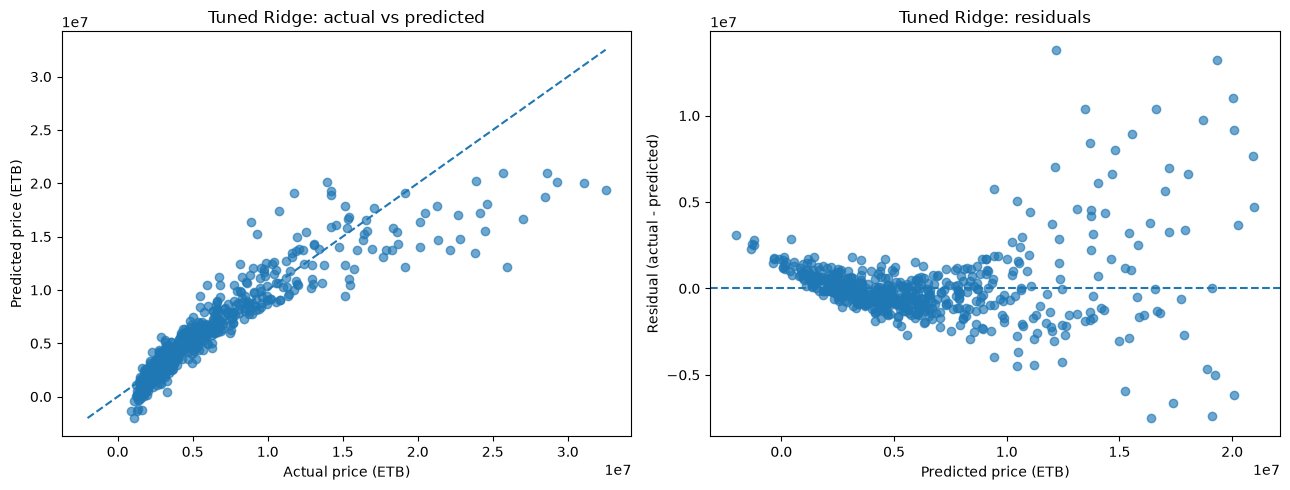

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, ridge_test_pred, alpha=0.65)
lo = min(float(y_test.min()), float(np.min(ridge_test_pred)))
hi = max(float(y_test.max()), float(np.max(ridge_test_pred)))
axes[0].plot([lo, hi], [lo, hi], linestyle="--")
axes[0].set_xlabel("Actual price (ETB)")
axes[0].set_ylabel("Predicted price (ETB)")
axes[0].set_title("Tuned Ridge: actual vs predicted")

residuals = y_test.to_numpy() - np.asarray(ridge_test_pred)
axes[1].scatter(ridge_test_pred, residuals, alpha=0.65)
axes[1].axhline(0, linestyle="--")
axes[1].set_xlabel("Predicted price (ETB)")
axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title("Tuned Ridge: residuals")

plt.tight_layout()
plt.show()

## 9. Inspect standardized coefficients

Coefficient magnitude gives the model's direction and relative strength after scaling. It is not proof of causation, and correlated predictors can make individual coefficients unstable.

In [11]:
ridge_model = best_ridge.named_steps["model"]
coef_table = pd.DataFrame({
    "Feature": FEATURES,
    "Standardized_Coefficient": ridge_model.coef_,
})
coef_table["Absolute_Coefficient"] = coef_table["Standardized_Coefficient"].abs()
display(coef_table.sort_values("Absolute_Coefficient", ascending=False).round(4))

,Feature,Standardized_Coefficient,Absolute_Coefficient
0,size_sqm,4.253091e+06,4.253091e+06
6,distance_to_bole_km,-1.367361e+06,1.367361e+06
4,age_years,-4.457030e+05,4.457030e+05
5,renovated,2.063126e+05,2.063126e+05
11,security_service,1.468024e+05,1.468024e+05
9,parking_spaces,1.124965e+05,1.124965e+05
10,has_garden,1.021332e+05,1.021332e+05
3,floor_level,-5.821182e+04,5.821182e+04
12,water_supply_hours_per_day,4.120203e+04,4.120203e+04
1,num_bedrooms,-3.697957e+04,3.697957e+04


## 10. Save outputs

In [12]:
output_dir = Path("outputs") / "metrics"
output_dir.mkdir(parents=True, exist_ok=True)

baseline_results.to_csv(output_dir / "07_ridge_baselines.csv", index=False)
final_results.to_csv(output_dir / "07_ridge_final_metrics.csv", index=False)
cv_results.to_csv(output_dir / "07_ridge_cv_results.csv", index=False)
coef_table.to_csv(output_dir / "07_ridge_coefficients.csv", index=False)

print("Saved Ridge results to:", output_dir.resolve())

Saved Ridge results to: C:\Users\hp\ML_Course\Notebooks\Regression\outputs\metrics


In [ ]:
## 11. What to explain 

- Ridge is linear regression with an L2 penalty that discourages very large coefficients.
- Standardization is used so predictors are on comparable scales before penalization.
- `alpha` is chosen using cross-validation on training data, not the test set.
- The test metrics estimate generalization to unseen rows from a similar distribution.
- If `days_on_market` is not available at the time of price prediction, remove it and rerun the experiment.

### Understanding check (answer before looking up anything)
1. What happens to coefficients as `alpha` becomes very large?
2. Why do we scale features for Ridge?
3. Why must the test set not be used to select `alpha`?
4. If Train_RMSE is much lower than Test_RMSE, what might that indicate?